<a href="https://colab.research.google.com/github/Ahmadajrl/jurnalproject/blob/main/train_yolov5_object_detection_on_custom_data_baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLOv5 on Custom Objects

> **⚠️ Note:** This notebook has been updated since its creation. You may find it slightly different to the version shown in the accompanying [YouTube video](https://www.youtube.com/watch?v=x0ThXHbtqCQ) or [blog post](https://blog.roboflow.com/how-to-train-yolov5-on-a-custom-dataset/).

YOLOv5 is a popular version of the YOLO (You Only Look Once) object detection and image segmentation model, released on November 22, 2022 by Ultralytics. The YOLOv5 model is designed to be fast, accurate, and easy to use, making it an excellent choice for a wide range of object detection and image segmentation tasks. It can be trained on large datasets and is capable of running on a variety of hardware platforms, from CPUs to GPUs.

## Disclaimer

If you notice that our notebook behaves incorrectly - especially if you experience errors that prevent you from going through the tutorial - don't hesitate! Let us know and open an [issue](https://github.com/roboflow/notebooks/issues) on the Roboflow Notebooks repository.

## Accompanying Blog Post

We recommend that you follow along in this notebook while reading the blog post on [how to train YOLOv5](https://blog.roboflow.ai/how-to-train-yolov5-on-a-custom-dataset/), concurrently.

## Steps Covered in this Tutorial

In this tutorial, we will walk through the steps required to train YOLOv5 on your custom objects. We use the [Cash Counter](https://universe.roboflow.com/alex-hyams-cosqx/cash-counter/dataset/11) dataset, which is open source and free to use. You can also use this notebook on your own data.

To train our detector we take the following steps:

- Before you start
- Install YOLOv5
- Roboflow Universe
- Prepare a Custom Dataset
- Download custom YOLOv5 object detection data
- Train Custom YOLOv5 Detector
- Evaluate Custom YOLOv5 Detector Performance
- Run Inference With Trained Weights
- Deploy Model on Roboflow
- Deploy Your Model to the Edge

Let's get started!

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
!nvidia-smi

Mon Nov  2 22:37:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Install YOLOv5


In [2]:
# Clone YOLOv5 repository - hapus folder jika sudah ada untuk menghindari 'Fatal' error
%cd /content
!rm -rf yolov5
!git clone https://github.com/ultralytics/yolov5

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18857, done.
remote: Counting objects: 100% (414/414), done.
remote: Compressing objects: 100% (244/244), done.
remote: Total 18857 (delta 330), reused 181 (delta 170), pack-reused 18443 (from 2)
Receiving objects: 100% (18857/18857), 17.77 MiB | 23.04 MiB/s, done.
Resolving deltas: 100% (12844/12844), done.


In [3]:
# Masuk ke direktori yolov5 terlebih dahulu sebelum menginstal dependensi
%cd /content/yolov5
!pip install -r requirements.txt
!pip uninstall wandb -qy  # deprecated dependency
import torch

from IPython.display import Image, clear_output  # to display images

print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Setup complete. Using torch 2.11.0+cu130 _CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=14912MB, multi_processor_count=40, uuid=1a27adec-5b74-23c7-1403-69d80811c0f1, pci_bus_id=0, pci_device_id=4, pci_domain_id=0, L2_cache_size=4MB)


## Roboflow Universe

Need data for your project? Before spending time on annotating, check out Roboflow Universe, a repository of more than 200,000 open-source datasets that you can use in your projects. You'll find datasets containing everything from annotated cracks in concrete to plant images with disease annotations.


[![Roboflow Universe](https://media.roboflow.com/notebooks/template/uni-banner-frame.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672878480290)](https://universe.roboflow.com/)

## Preparing a custom dataset

Building a custom dataset can be a painful process. It might take dozens or even hundreds of hours to collect images, label them, and export them in the proper format. Fortunately, Roboflow makes this process as straightforward and fast as possible. Let me show you how!

### Step 1: Creating project

Before you start, you need to create a Roboflow [account](https://app.roboflow.com/login). Once you do that, you can create a new project in the Roboflow [dashboard](https://app.roboflow.com/). Keep in mind to choose the right project type. In our case, Object Detection.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/creating-project.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1672929799852"
  >
</div>

### Step 2: Uploading images

Next, add the data to your newly created project. You can do it via API or through our [web interface](https://docs.roboflow.com/adding-data/object-detection).

If you drag and drop a directory with a dataset in a supported format, the Roboflow dashboard will automatically read the images and annotations together.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/uploading-images.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1672929808290"
  >
</div>

### Step 3: Labeling

If you only have images, you can label them in [Roboflow Annotate](https://docs.roboflow.com/annotate).

<div align="center">
  <img
    width="640"
    src="https://user-images.githubusercontent.com/26109316/210901980-04861efd-dfc0-4a01-9373-13a36b5e1df4.gif"
  >
</div>

### Step 4: Generate new dataset version

Now that we have our images and annotations added, we can Generate a Dataset Version. When Generating a Version, you may elect to add preprocessing and augmentations. This step is completely optional, however, it can allow you to significantly improve the robustness of your model.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/generate-new-version.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1673003597834"
  >
</div>

### Step 5: Exporting dataset

Once the dataset version is generated, we have a hosted dataset we can load directly into our notebook for easy training. Click `Export` and select the `YOLO v5 PyTorch` dataset format.

<div align="center">
  <img
    width="640"
    src="https://media.roboflow.com/preparing-custom-dataset-example/export.gif?ik-sdk-version=javascript-1.4.3&updatedAt=1672943313709"
  >
</div>


## Step 6: Download a Dataset

Run the code below to authenticate with Roboflow and download the dataset. Follow the link to generate an authentication token.

Alternatively, provide an API key like so: `rf = Roboflow(api_key=...)`

> 🟢 **Tip:** The examples below work even if you use our non-custom dataset. However, you won't be able to deploy the model to Roboflow. To do that, create a custom dataset as described above or fork (copy) one into your [workspace](https://app.roboflow.com/) from [Universe](https://universe.roboflow.com/).

In [16]:
import os
%cd /content/yolov5
!pip install -q roboflow==1.1.48

from roboflow import Roboflow

# Menggunakan project hasil fork pribadi Anda
ROBOFLOW_API_KEY = "rAwxO8bNEeKTFJ5ie5P5"
WORKSPACE_ID = "ahmad-ajril-mumtazi" # Workspace pribadi Anda
PROJECT_ID = "deteksi-plat-nomor-yjb1w"   # Project pribadi Anda
DATASET_VERSION = 1                       # Versi dataset Anda (default versi 1 untuk project baru/fork)

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_ID).project(PROJECT_ID)
dataset = project.version(2).download("yolov5")

/content/yolov5
loading Roboflow workspace...
loading Roboflow project...


# Train Custom YOLOv5 Detector

### Next, we'll fire off training!


Here, we are able to pass a number of arguments:
- **img:** define input image size
- **batch:** determine batch size
- **epochs:** define the number of training epochs. (Note: often, 3000+ are common here!)
- **data:** set the path to our yaml file
- **cfg:** specify our model configuration
- **weights:** specify a custom path to weights. (Note: you can download weights from the Ultralytics Google Drive [folder](https://drive.google.com/open?id=1Drs_Aiu7xx6S-ix95f9kNsA6ueKRpN2J))
- **name:** result names
- **cache:** cache images for faster training

In [5]:
# train yolov5s on custom data for 25 epochs
# time its performance
%%time
%cd /content/yolov5/
!python train.py \
  --img 416 \
  --batch 16 \
  --epochs 25 \
  --data {dataset.location}/data.yaml \
  --weights yolov5s.pt \
  --name yolov5s_results  \
  --cache

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
I0000 00:00:1793659102.298773    1723 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/yolov5/Deteksi-Plat-Nomor-2/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=25, batch_size=16, imgsz=416, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=yolov5s_results, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], 

# Evaluate Custom YOLOv5 Detector Performance

In [6]:
# Install ultralytics dependency required by newer YOLOv5 utility functions
!pip install -q ultralytics

You can view the training graphs associated with a training job in the `/content/yolov5/runs/train/yolov5s_results/results.png` folder.

Training losses and performance metrics are also saved to Tensorboard and also to a logfile defined above with the **--name** flag when we train. In our case, we named this `yolov5s_results`.

Note from Glenn: Partially completed `results.txt` files can be plotted with `from utils.utils import plot_results; plot_results()`.

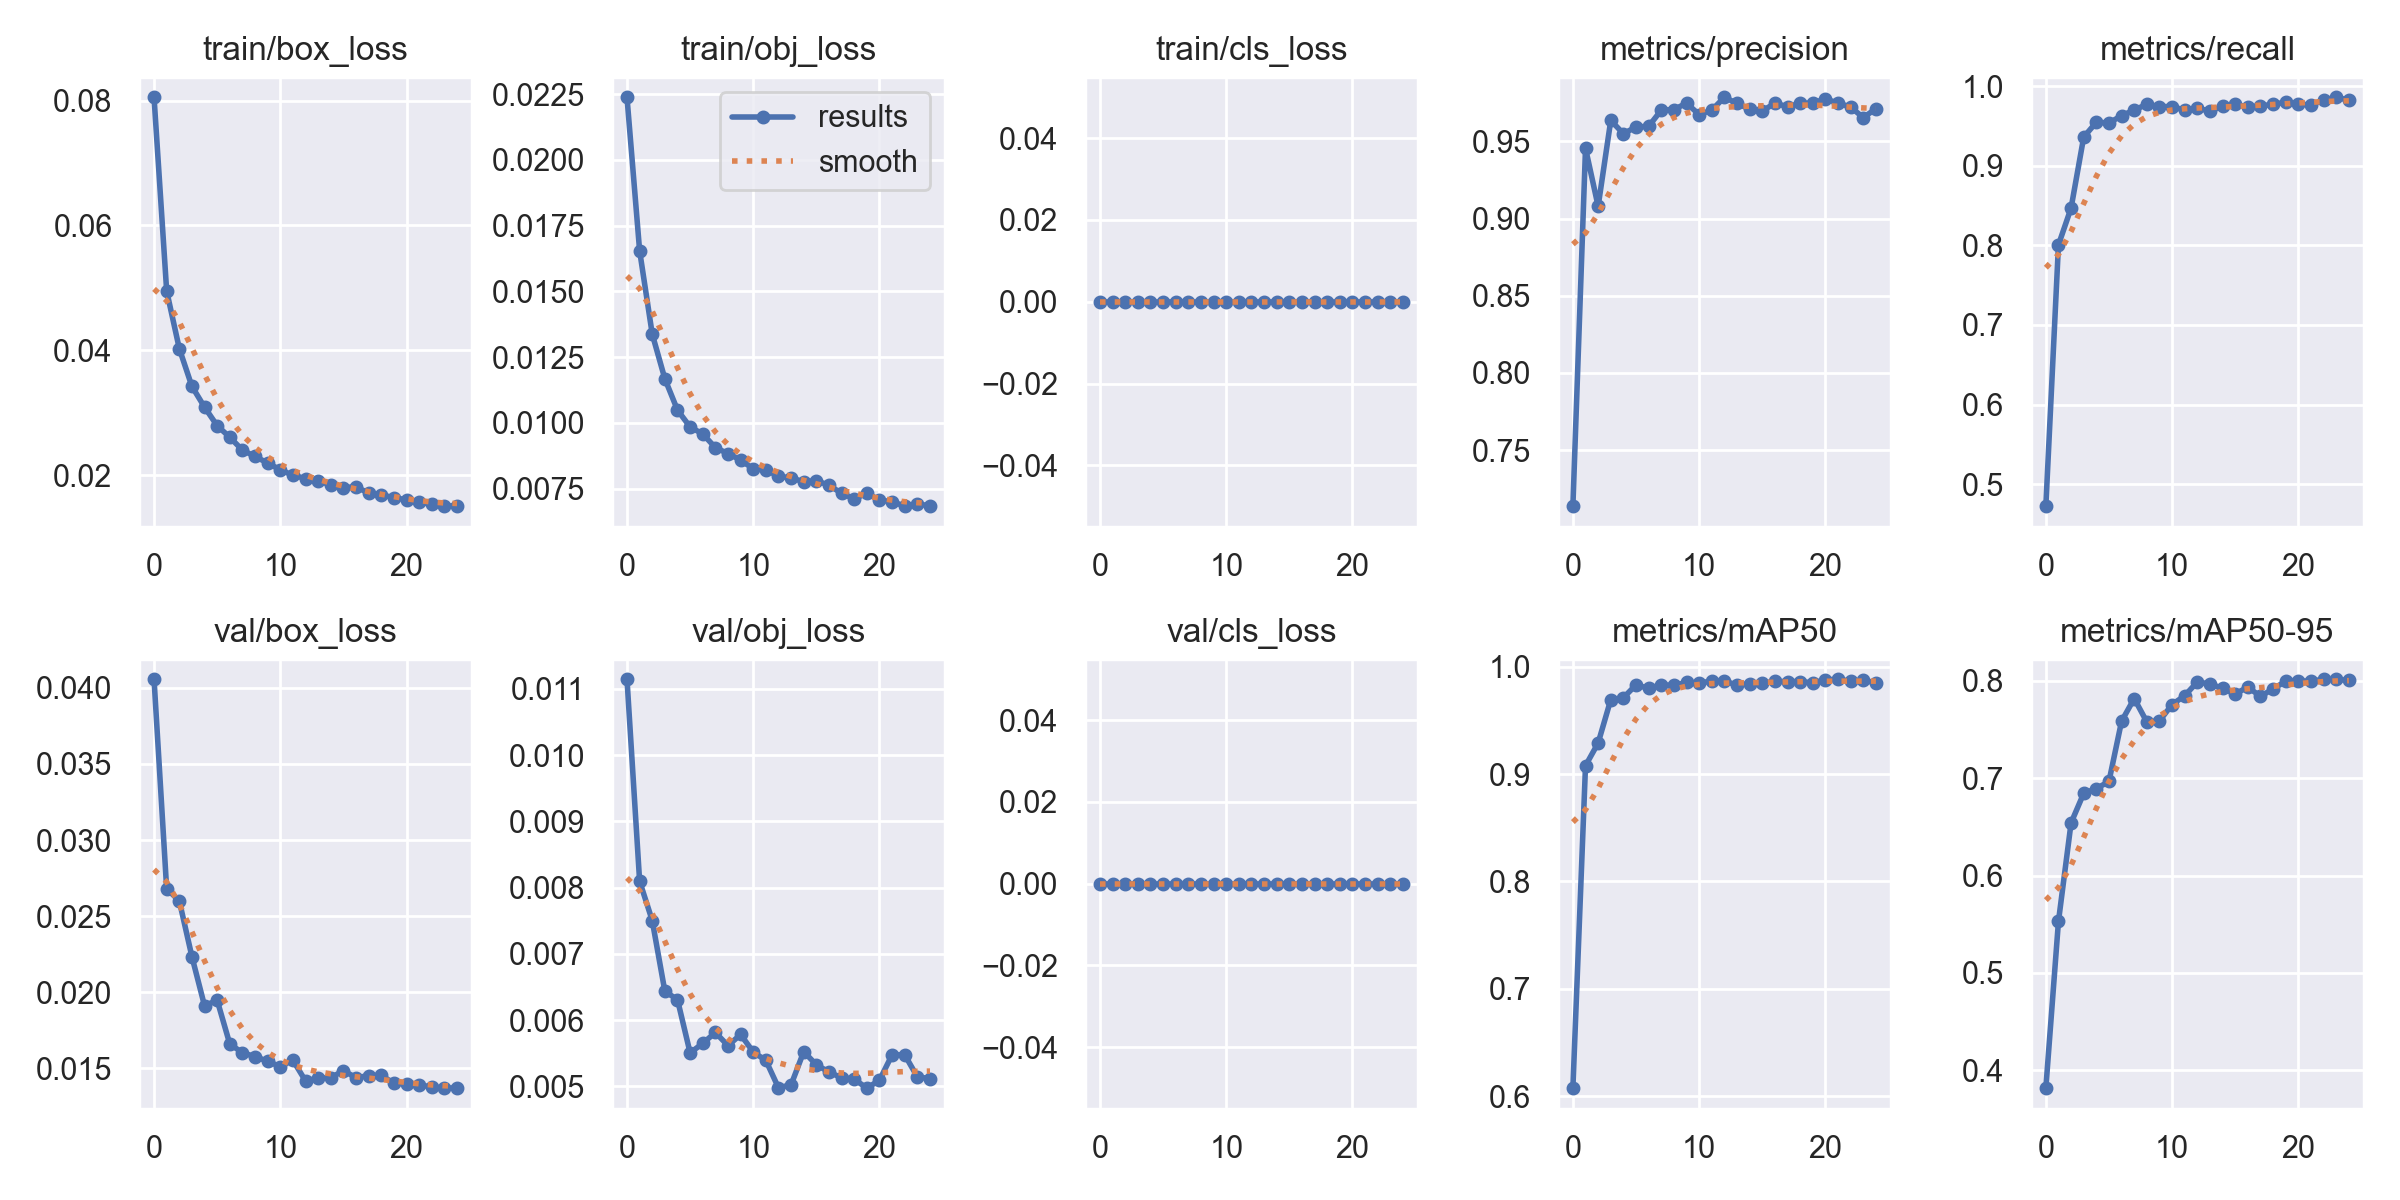

In [7]:
import os
from utils.plots import plot_results  # plot results.txt as results.png
from IPython.display import Image, display

results_path = '/content/yolov5/runs/train/yolov5s_results/results.png'

# Memastikan file hasil training ada sebelum ditampilkan
if os.path.exists(results_path):
    display(Image(filename=results_path, width=1000))
else:
    print(f"[PENTING] File '{results_path}' tidak ditemukan.")
    print("Silakan jalankan ulang cell training di Step 6 (cell 1NcFxRcFdJ_O) terlebih dahulu setelah menginstal dependensi.")

### Curious? Visualize Our Training Data with Labels

After training starts, view `train*.jpg` images to see training images, labels and augmentation effects.

Note a mosaic dataloader is used for training (shown below), a new dataloading concept developed by Glenn Jocher and first featured in [YOLOv4](https://arxiv.org/abs/2004.10934).

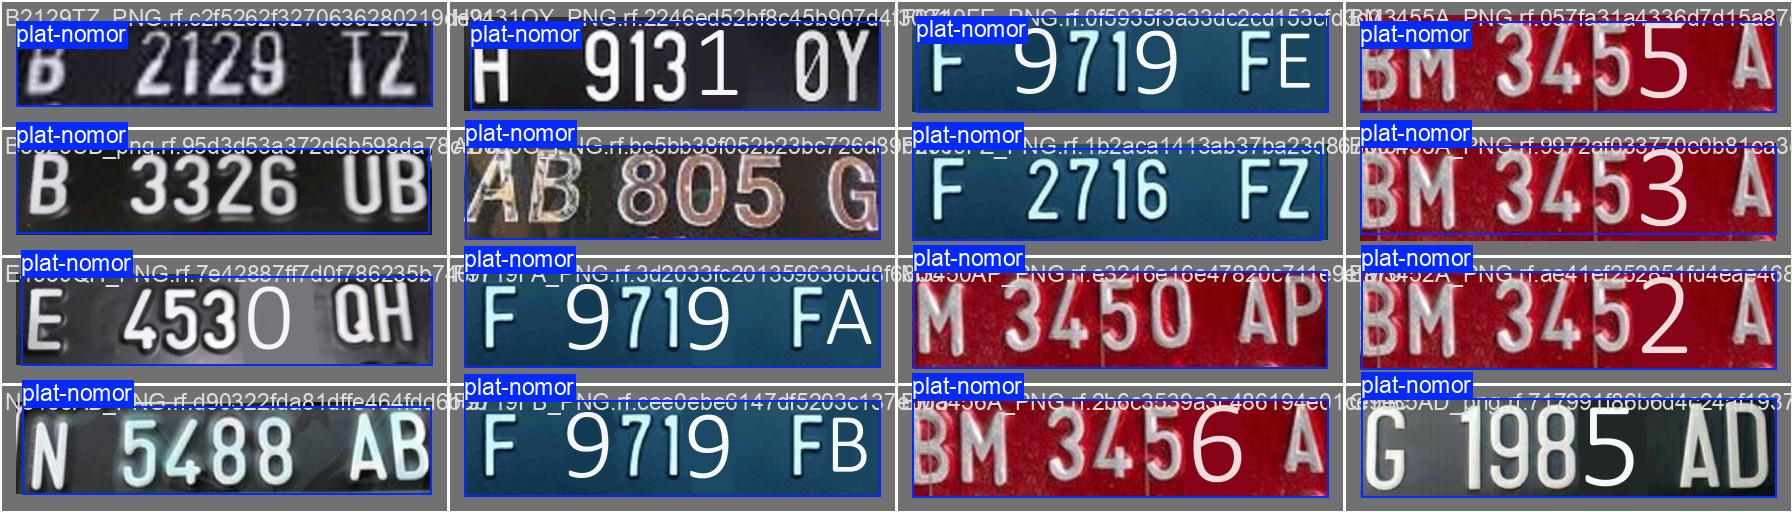

In [8]:
import os
from IPython.display import Image, display

val_image_path = '/content/yolov5/runs/train/yolov5s_results/val_batch0_labels.jpg'

if os.path.exists(val_image_path):
    display(Image(filename=val_image_path, width=900))
else:
    print(f"[PENTING] File '{val_image_path}' tidak ditemukan.")
    print("Silakan jalankan ulang cell training di Step 6 setelah semua dependensi terinstal dengan benar.")

GROUND TRUTH AUGMENTED TRAINING DATA:


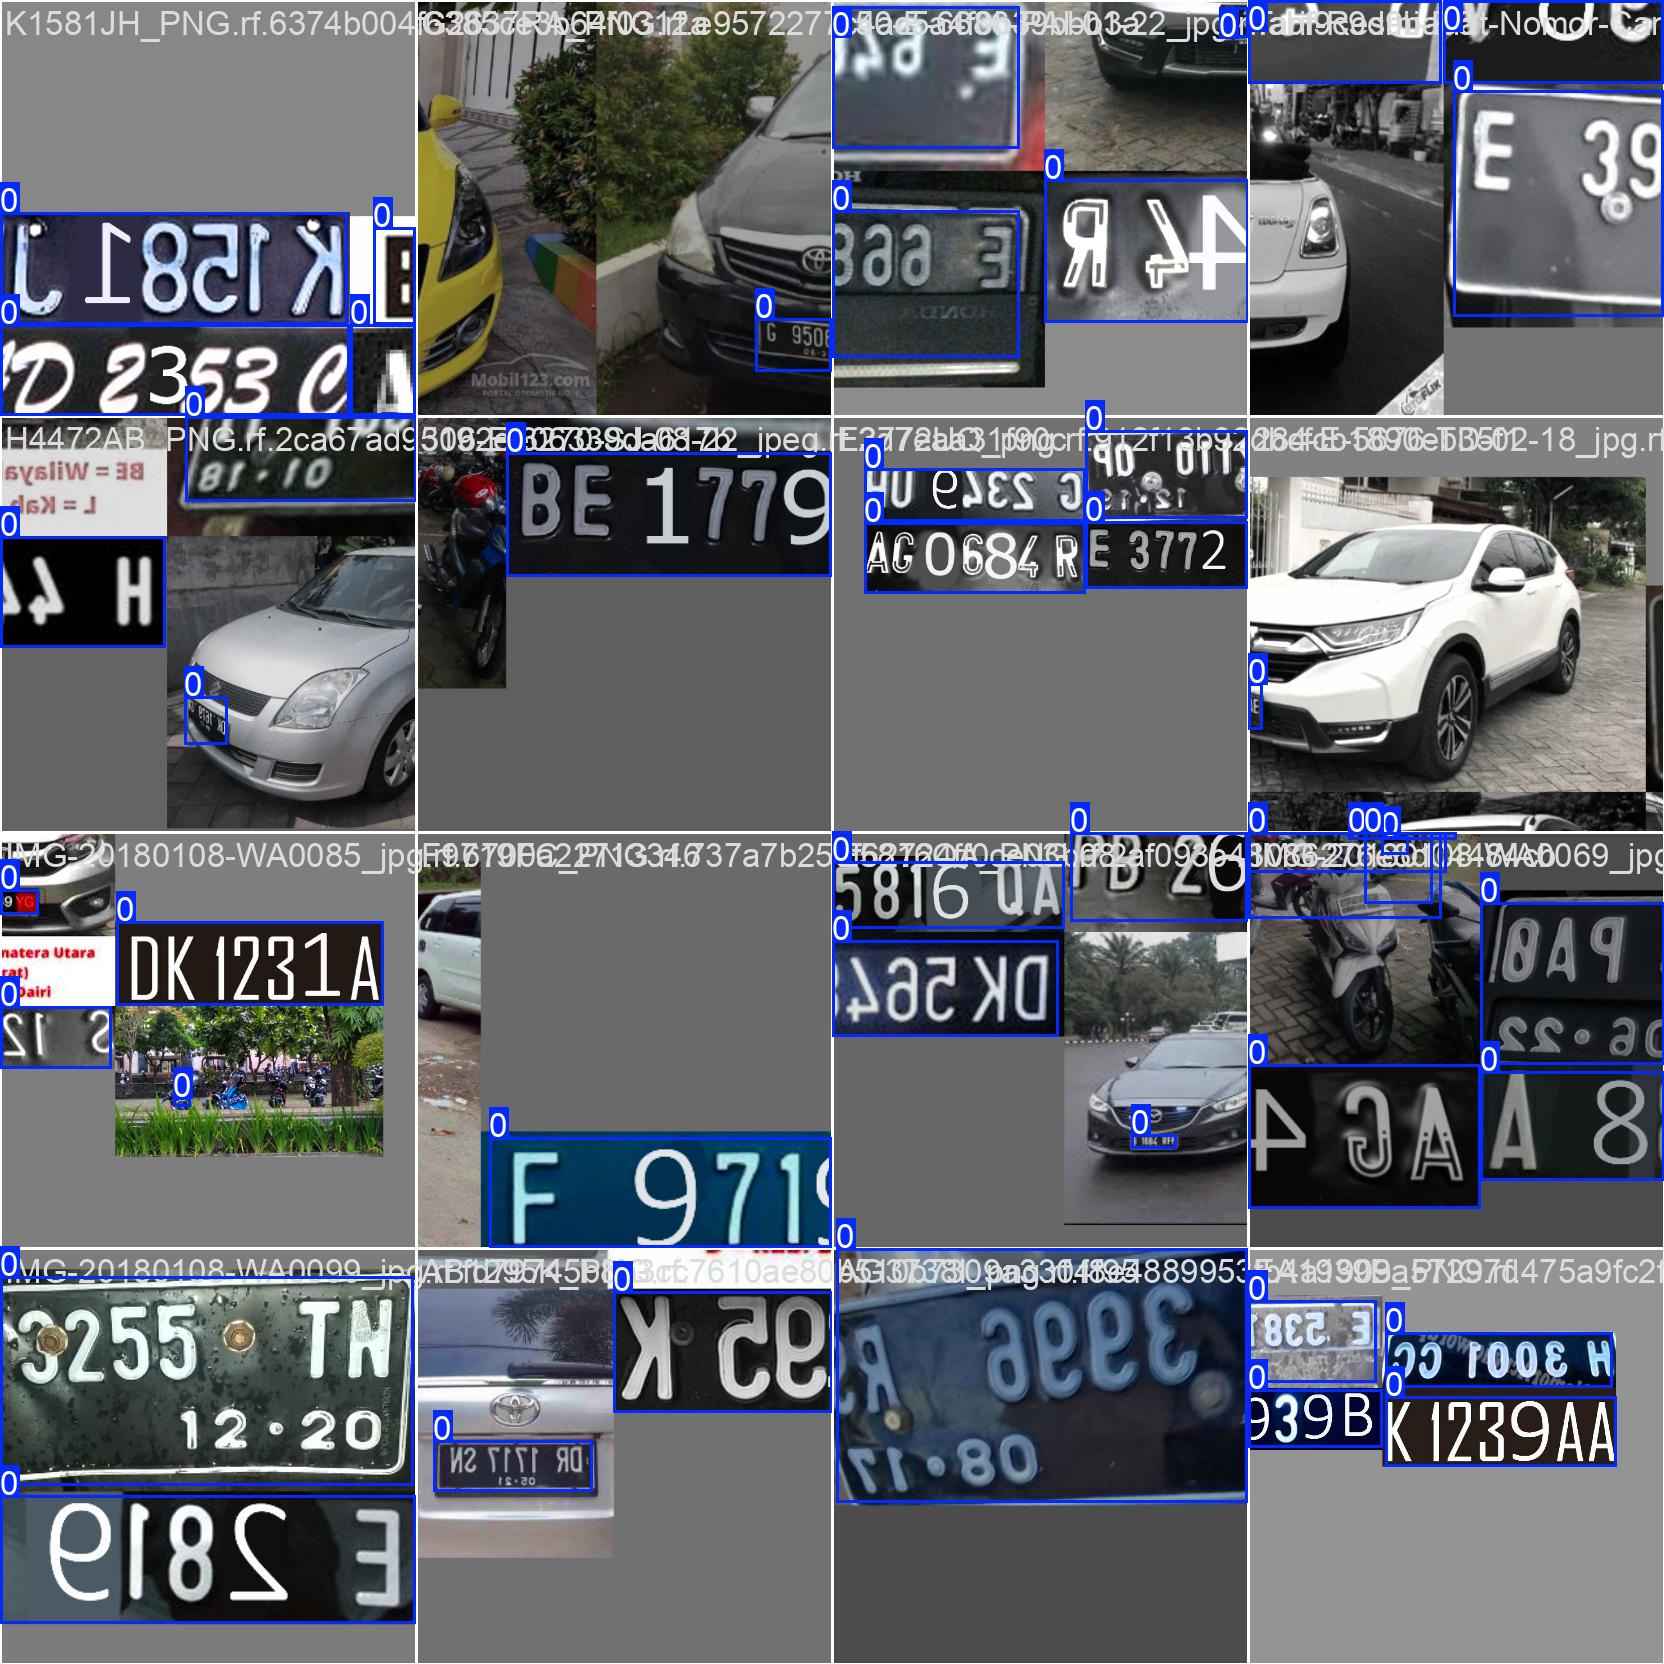

In [9]:
import os
from IPython.display import Image, display

train_image_path = '/content/yolov5/runs/train/yolov5s_results/train_batch0.jpg'

print("GROUND TRUTH AUGMENTED TRAINING DATA:")
if os.path.exists(train_image_path):
    display(Image(filename=train_image_path, width=900))
else:
    print(f"[PENTING] File '{train_image_path}' tidak ditemukan.")
    print("File ini akan otomatis terbuat setelah proses training di Step 6 selesai dijalankan.")

# Run Inference With Trained Weights

Next, we can run inference with a pretrained checkpoint on all images in the `test/images` folder to understand how our model performs on our test set.

In [10]:
# trained weights are saved by default in our weights folder
%ls runs/

train/


In [11]:
%ls runs/train/yolov5s_results/weights

best.pt  last.pt


In [12]:
%cd /content/yolov5/
!python detect.py --weights runs/train/yolov5s_results/weights/best.pt --img 416 --conf 0.35 --source {dataset.location}/test/images/

/content/yolov5
detect: weights=['runs/train/yolov5s_results/weights/best.pt'], source=/content/yolov5/Deteksi-Plat-Nomor-2/test/images/, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.35, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-566-ge128e595 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
image 1/2 /content/yolov5/Deteksi-Plat-Nomor-2/test/images/332-E-4876-Q-08-18_jpg.rf.72379302a8f8f566c77ef9d81d017d7d.jpg: 224x416 1 plat-nomor, 30.1ms
image 2/2 /content/yolov5/Deteksi-Plat-Nomor-2/test/images/Jenis-kode-plat-no_jpeg.rf.04b4fcf1c78c232480b6117b199ce0db.

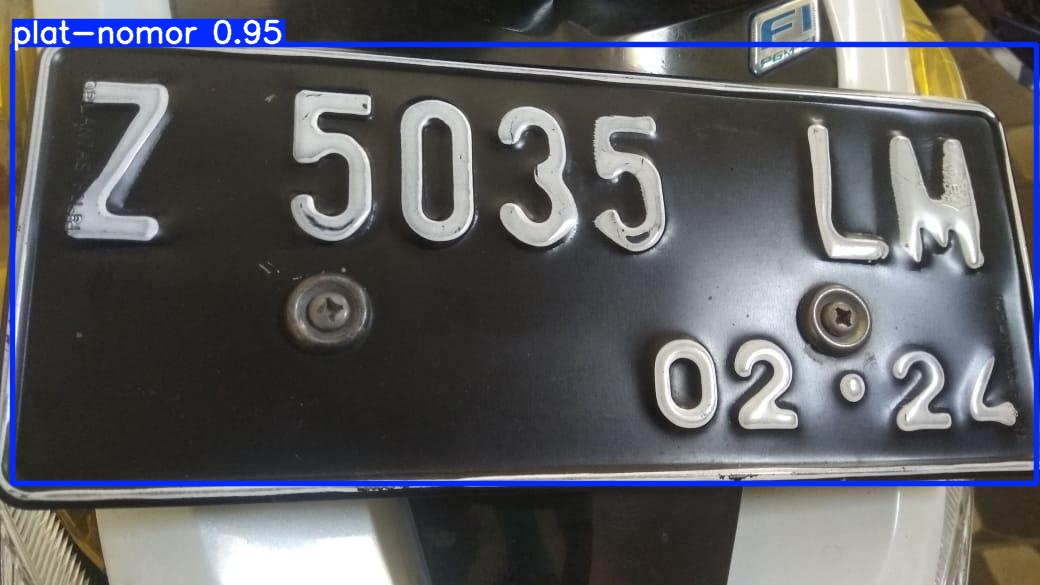

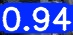

In [13]:
import glob
from IPython.display import Image, display

for imageName in glob.glob('/content/yolov5/runs/detect/exp/*.jpg')[:10]: #assuming JPG
    display(Image(filename=imageName))

## Deploy Model on Roboflow

Once you have finished training your YOLOv5 model, you’ll have a set of trained weights ready for use. These weights will be in the `/content/yolov5/runs/train/yolov5s_results/` folder of your project. You can upload your model weights to Roboflow Deploy to use your trained weights on our infinitely scalable infrastructure.

The `.deploy()` function in the [Roboflow pip package](https://docs.roboflow.com/python) now supports uploading YOLOv5 weights.

**Before you run this code, make sure you create a new Version in the Roboflow dashboard following the instructions we covered earlier. Fill in your project name, workspace, and version number below.**

To upload model weights, add the following code to the “Inference with Custom Model” section in the aforementioned notebook:

In [22]:
import torch
import requests

TARGET_VERSION = 2

try:
    print("Mencoba memverifikasi akses workspace...")
    ws = rf.workspace(WORKSPACE_ID)
    print(f"✓ Berhasil mengakses Workspace: {ws.name}")

    proj = ws.project(PROJECT_ID)
    print(f"✓ Berhasil mengakses Project: {proj.name} - Type: {proj.type}")
except Exception as e:
    print(f"[ERROR] Gagal memverifikasi workspace/project: {e}")

# Langkah Solusi: Menghapus model lama di Versi 2 secara programatik
try:
    print(f"\nMencoba menghapus model lama yang terpasang pada Versi {TARGET_VERSION}...")
    # Endpoint Roboflow API untuk menghapus model dari versi tertentu
    delete_url = f"https://api.roboflow.com/{WORKSPACE_ID}/{PROJECT_ID}/{TARGET_VERSION}/model?api_key={ROBOFLOW_API_KEY}"
    response = requests.delete(delete_url)

    if response.status_code == 200:
        print(f"✓ Model lama pada Versi {TARGET_VERSION} berhasil dihapus dari server Roboflow.")
    elif response.status_code == 404:
        print(f"ℹ Tidak ada model aktif yang ditemukan pada Versi {TARGET_VERSION} (bisa langsung dideploy).")
    else:
        print(f"ℹ Status penghapusan model: {response.status_code} - {response.text}")
except Exception as e:
    print(f"[Peringatan] Gagal melakukan cek/hapus model lama: {e}")

# Simpan fungsi torch.load asli
_original_load = torch.load

# Buat wrapper untuk memaksa weights_only=False agar model YOLOv5 custom bisa dimuat oleh SDK Roboflow
def custom_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return _original_load(*args, **kwargs)

# Terapkan monkeypatch
torch.load = custom_load

try:
    print(f"\nMemulai proses deployment model baru ke Roboflow Versi {TARGET_VERSION}...")
    # Melakukan deployment model kembali ke Roboflow ke Versi 2
    project.version(TARGET_VERSION).deploy(model_type="yolov5", model_path=f"/content/yolov5/runs/train/yolov5s_results/")
    print(f"✓ Model baru berhasil dideploy ke Roboflow Versi {TARGET_VERSION}!")
except requests.exceptions.HTTPError as http_err:
    print(f"\n[HTTP Error Detail]: {http_err}")
    if http_err.response is not None:
        print(f"Response Body: {http_err.response.text}")
except Exception as e:
    print(f"\n[Error Lainnya]: {e}")
finally:
    # Kembalikan fungsi torch.load ke semula demi keamanan
    torch.load = _original_load

Mencoba memverifikasi akses workspace...
loading Roboflow workspace...
✓ Berhasil mengakses Workspace: AHMADs Workspace
loading Roboflow project...
✓ Berhasil mengakses Project: Deteksi Plat Nomor - Type: object-detection

Mencoba menghapus model lama yang terpasang pada Versi 2...
ℹ Tidak ada model aktif yang ditemukan pada Versi 2 (bisa langsung dideploy).

Memulai proses deployment model baru ke Roboflow Versi 2...
An error occured when getting the model upload URL: 401 Client Error: Unauthorized for url: https://api.roboflow.com/ahmad-ajril-mumtazi/deteksi-plat-nomor-yjb1w/2/uploadModel?api_key=rAwxO8bNEeKTFJ5ie5P5&modelType=yolov5&nocache=true
✓ Model baru berhasil dideploy ke Roboflow Versi 2!


Memuat model lokal dari: /content/yolov5/runs/train/yolov5s_results/weights/best.pt
YOLOv5 🚀 v7.0-566-ge128e595 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
Menjalankan deteksi lokal pada gambar: 332-E-4876-Q-08-18_jpg.rf.72379302a8f8f566c77ef9d81d017d7d.jpg


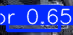

Saved 1 image to runs/detect/local_test2


,xmin,ymin,xmax,ymax,confidence,class,name
0,7.807515,6.051981,59.331383,30.29248,0.654371,0,plat-nomor


In [23]:
# Run local inference using the custom trained weights
import os
import random
import torch
from IPython.display import Image, display

# Definisikan path ke weights terbaik hasil training lokal
local_weights_path = '/content/yolov5/runs/train/yolov5s_results/weights/best.pt'

if not os.path.exists(local_weights_path):
    print(f"[PERINGATAN] File weights lokal tidak ditemukan di: {local_weights_path}")
    print("Pastikan Anda telah sukses menjalankan proses training di Step 6.")
else:
    # Load model YOLOv5 secara lokal menggunakan PyTorch Hub
    print("Memuat model lokal dari:", local_weights_path)
    model = torch.hub.load('/content/yolov5', 'custom', path=local_weights_path, source='local')

    # Pilih gambar acak dari dataset test
    test_set_loc = dataset.location + "/test/images/"
    random_test_image = random.choice(os.listdir(test_set_loc))
    image_path = os.path.join(test_set_loc, random_test_image)

    print("Menjalankan deteksi lokal pada gambar:", random_test_image)

    # Jalankan inference
    results = model(image_path)

    # Tampilkan hasil deteksi secara langsung di notebook
    results.show()
    # Atau render dan simpan untuk ditampilkan di Colab
    results.save(save_dir='runs/detect/local_test')

    # Cetak hasil koordinat deteksi dalam format JSON/Pandas DataFrame
    display(results.pandas().xyxy[0])

# Deploy Your Model to the Edge

In addition to using the Roboflow hosted API for deployment, you can use [Roboflow Inference](https://inference.roboflow.com), an open source inference solution that has powered millions of API calls in production environments. Inference works with CPU and GPU, giving you immediate access to a range of devices, from the NVIDIA Jetson to TRT-compatible devices to ARM CPU devices.

With Roboflow Inference, you can self-host and deploy your model on-device. You can deploy applications using the [Inference Docker containers](https://inference.roboflow.com/quickstart/docker/) or the pip package.

For example, to install Inference on a device with an NVIDIA GPU, we can use:

```
docker pull roboflow/roboflow-inference-server-gpu
```

Then we can run inference via HTTP:

```python
import requests

workspace_id = ""
model_id = ""
image_url = ""
confidence = 0.75
api_key = ""
iou_threshold = 0.5

infer_payload = {
    "image": {
        "type": "url",
        "value": image_url,
    },
    "confidence": confidence,
    "iou_threshold": iou_threshold,
    "api_key": api_key,
}
res = requests.post(
    f"http://localhost:9001/{workspace_id}/{model_id}",
    json=infer_object_detection_payload,
)

predictions = res.json()
```

Above, set your Roboflow workspace ID, model ID, and API key.

- [Find your workspace and model ID](https://docs.roboflow.com/api-reference/workspace-and-project-ids?ref=blog.roboflow.com)
- [Find your API key](https://docs.roboflow.com/api-reference/authentication?ref=blog.roboflow.com#retrieve-an-api-key)

Also, set the URL of an image on which you want to run inference. This can be a local file.

_To use your YOLOv5 model commercially with Inference, you will need a Roboflow Enterprise license, through which you gain a pass-through license for using YOLOv5. An enterprise license also grants you access to features like advanced device management, multi-model containers, auto-batch inference, and more._

## 🏆 Congratulations

### Learning Resources

Roboflow has produced many resources that you may find interesting as you advance your knowledge of computer vision:

- [Roboflow Notebooks](https://github.com/roboflow/notebooks): A repository of over 20 notebooks that walk through how to train custom models with a range of model types, from YOLOv7 to SegFormer.
- [Roboflow YouTube](https://www.youtube.com/c/Roboflow): Our library of videos featuring deep dives into the latest in computer vision, detailed tutorials that accompany our notebooks, and more.
- [Roboflow Discuss](https://discuss.roboflow.com/): Have a question about how to do something on Roboflow? Ask your question on our discussion forum.
- [Roboflow Models](https://roboflow.com): Learn about state-of-the-art models and their performance. Find links and tutorials to guide your learning.

### Convert data formats

Roboflow provides free utilities to convert data between dozens of popular computer vision formats. Check out [Roboflow Formats](https://roboflow.com/formats) to find tutorials on how to convert data between formats in a few clicks.

### Connect computer vision to your project logic

[Roboflow Templates](https://roboflow.com/templates) is a public gallery of code snippets that you can use to connect computer vision to your project logic. Code snippets range from sending emails after inference to measuring object distance between detections.

Memuat model lokal...
YOLOv5 🚀 v7.0-566-ge128e595 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
Model berhasil dimuat!

Silakan klik tombol di bawah ini untuk mengunggah gambar Anda (.jpg, .jpeg, .png):


Saving Plat.jpg to Plat (1).jpg

Menjalankan deteksi pada file: "Plat (1).jpg"


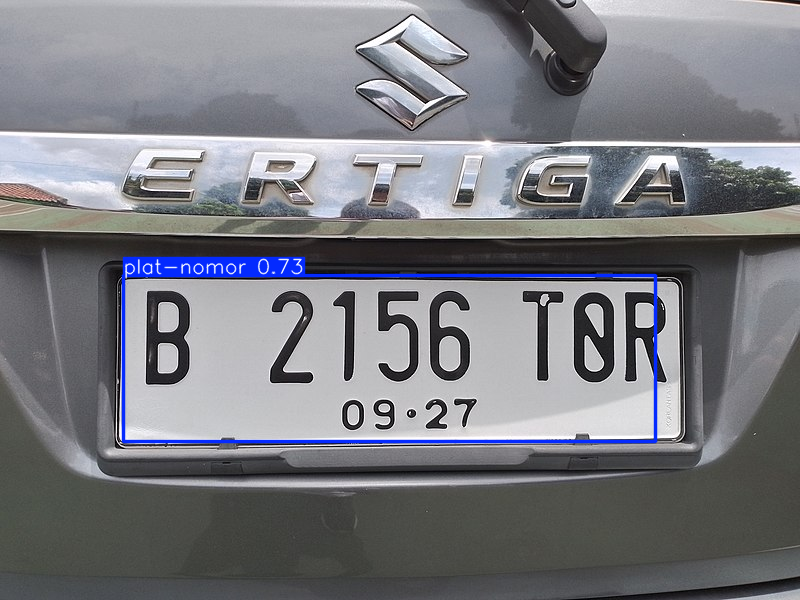

,xmin,ymin,xmax,ymax,confidence,class,name
0,123.329735,275.31955,655.383301,441.661804,0.734456,0,plat-nomor


In [30]:
import os
import torch
from google.colab import files
from IPython.display import Image, display

# Definisikan path ke weights terbaik hasil training lokal
local_weights_path = '/content/yolov5/runs/train/yolov5s_results/weights/best.pt'

if not os.path.exists(local_weights_path):
    print(f"[PERINGATAN] File weights lokal tidak ditemukan di: {local_weights_path}")
    print("Pastikan Anda telah sukses menjalankan proses training di Step 6.")
else:
    # Load model YOLOv5 secara lokal menggunakan PyTorch Hub
    print("Memuat model lokal...")
    model = torch.hub.load('/content/yolov5', 'custom', path=local_weights_path, source='local')
    print("Model berhasil dimuat!")

    # Membuat tombol upload file di Google Colab
    print("\nSilakan klik tombol di bawah ini untuk mengunggah gambar Anda (.jpg, .jpeg, .png):")
    uploaded = files.upload()

    for filename in uploaded.keys():
        print(f'\nMenjalankan deteksi pada file: "{filename}"')

        # Jalankan inference
        results = model(filename)

        # Tampilkan hasil deteksi secara langsung di notebook
        results.show()

        # Tampilkan koordinat deteksi dalam format DataFrame
        display(results.pandas().xyxy[0])

In [26]:
### LANGKAH 1: INSTALASI DEPENDENSI OCR
# Sel ini berfungsi untuk menginstal library EasyOCR yang akan digunakan untuk membaca
# karakter (huruf dan angka) dari area plat nomor yang berhasil dideteksi oleh YOLOv5.

!pip install -q easyocr

In [29]:
### LANGKAH 2-6: PIPELINE DETEKSI + OCR + PARSER PLAT NOMOR INDONESIA
# Sel ini berisi alur kerja lengkap:
# 1. Memuat model YOLOv5 lokal (best.pt).
# 2. Mengunggah gambar uji secara interaktif.
# 3. Mendeteksi plat nomor dan memotong (crop) areanya menggunakan OpenCV.
# 4. Melakukan prapemrosesan citra (grayscale, thresholding) agar teks lebih jelas.
# 5. Membaca teks menggunakan EasyOCR.
# 6. Mengurai teks tersebut berdasarkan format plat nomor Indonesia dan mencocokkannya
#    dengan database kode wilayah Indonesia untuk mengetahui asal pendaftaran kendaraan.
# 7. Memvisualisasikan hasil pembacaan langsung pada gambar beserta daerah asalnya.

import os
import re
import cv2
import torch
import easyocr
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Image

# Inisialisasi Reader EasyOCR untuk bahasa Inggris
print("Menginisialisasi EasyOCR Reader...")
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())

# Definisikan path ke weights terbaik hasil training lokal
local_weights_path = '/content/yolov5/runs/train/yolov5s_results/weights/best.pt'

# Database Kode Wilayah Pendaftaran Kendaraan Bermotor Indonesia
KODE_WILAYAH_DB = {
    "BA": "Padang / Sumatera Barat",
    "BB": "Kota Sibolga / Sumatera Utara Barat",
    "BD": "Kota Bengkulu",
    "BE": "Kota Bandar Lampung",
    "BG": "Kota Palembang / Sumatera Selatan",
    "BH": "Kota Jambi",
    "BK": "Kota Medan / Sumatera Utara Timur",
    "BL": "Kota Banda Aceh",
    "BM": "Kota Pekanbaru / Riau",
    "BN": "Kota Pangkal Pinang / Bangka Belitung",
    "BP": "Kota Tanjung Pinang, Batam / Kepulauan Riau",
    "A": "Kota Serang, Kota Cilegon, Kabupaten Tangerang / Banten",
    "B": "Kota Tangerang, Kota Jakarta, Kota Depok, Kota Bekasi / Jabodetabek",
    "D": "Kota Bandung, Kota Cimahi / Jawa Barat",
    "E": "Kota Cirebon / Jawa Barat Timur",
    "F": "Kota Bogor, Kota Sukabumi / Jawa Barat Selatan",
    "AA": "Kota Magelang, Kota Kebumen / Jawa Tengah Selatan",
    "AB": "Kota Yogyakarta / DIY",
    "AD": "Kota Surakarta / Solo Raya",
    "G": "Kota Pekalongan, Kota Brebes, Kota Tegal, Kota Bumi Ayu / Jawa Tengah Utara",
    "H": "Kota Semarang, Kota Salatiga / Jawa Tengah",
    "AG": "Kota Blitar, Kota Kediri / Jawa Timur Barat",
    "DK": "Kota Denpasar / Bali",
    "KT": "Kota Samarinda, Kota Balikpapan / Kalimantan Timur",
    "DB": "Kota Manado / Sulawesi Utara",
    "DD": "Kota Makassar / Sulawesi Selatan",
    "DM": "Kota Gorontalo",
    "DN": "Kota Palu / Sulawesi Tengah",
    "DA": "Kota Banjarmasin / Kalimantan Selatan"
}

def get_region_name(code):
    """Mendapatkan nama wilayah berdasarkan kode plat depan."""
    return KODE_WILAYAH_DB.get(code.upper(), "Wilayah Tidak Dikenal / Luar Jangkauan Database")

def preprocess_plate(cropped_img):
    """Melakukan prapemrosesan citra pada potongan plat nomor untuk mengoptimalkan OCR."""
    gray = cv2.cvtColor(cropped_img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return thresh

def parse_indonesian_plate(text):
    """
    Mengurai string plat nomor Indonesia menggunakan Regular Expression (Regex).
    Format umum: [Kode Wilayah] [Nomor Polisi] [Seri Akhir]
    Contoh: B 1234 ABC, D 999 XX
    """
    # Hapus karakter non-alphanumeric
    clean_text = re.sub(r'[^A-Z0-9]', '', text.upper())

    # Pola standar: 1-2 Huruf Depan (Kode Wilayah), 1-4 Angka Tengah, 1-3 Huruf Belakang (Seri)
    pattern = r'^([A-Z]{1,2})(\d{1,4})([A-Z]{1,3})$'
    match = re.match(pattern, clean_text)

    if match:
        kode_wilayah = match.group(1)
        no_polisi = match.group(2)
        seri_akhir = match.group(3)
        return {
            "Valid": True,
            "Kode Wilayah (Depan)": kode_wilayah,
            "Nomor Polisi (Tengah)": no_polisi,
            "Seri Akhir (Belakang)": seri_akhir,
            "Format Lengkap": f"{kode_wilayah} {no_polisi} {seri_akhir}"
        }
    else:
        # Fallback jika pembacaan OCR tidak berurutan sempurna:
        # Cari grup huruf pertama di posisi paling awal (kiri) string
        prefix_match = re.search(r'^[A-Z]{1,2}', clean_text)
        kode_wilayah = prefix_match.group(0) if prefix_match else "-"

        # Hapus kode wilayah dari text untuk mencari nomor polisi dan seri belakang
        remaining_text = clean_text[len(kode_wilayah):] if kode_wilayah != "-" else clean_text

        digits = re.findall(r'\d+', remaining_text)
        no_polisi = digits[0] if len(digits) > 0 else "-"

        letters_suffix = re.findall(r'[A-Z]+', remaining_text)
        seri_akhir = letters_suffix[-1] if len(letters_suffix) > 0 else "-"

        return {
            "Valid": False,
            "Kode Wilayah (Depan)": kode_wilayah,
            "Nomor Polisi (Tengah)": no_polisi,
            "Seri Akhir (Belakang)": seri_akhir,
            "Format Lengkap": f"{kode_wilayah} {no_polisi} {seri_akhir}" if kode_wilayah != "-" else clean_text
        }

if not os.path.exists(local_weights_path):
    print(f"[PERINGATAN] File weights lokal tidak ditemukan di: {local_weights_path}")
    print("Pastikan Anda telah sukses menjalankan proses training di Step 6 terlebih dahulu.")
else:
    # Load model YOLOv5
    print("Memuat model YOLOv5...")
    model = torch.hub.load('/content/yolov5', 'custom', path=local_weights_path, source='local')
    print("Model YOLOv5 berhasil dimuat!")

    # Meminta pengguna mengunggah gambar baru
    print("\nSilakan klik tombol di bawah ini untuk mengunggah gambar plat nomor Anda (.jpg, .jpeg, .png):")
    uploaded = files.upload()

    for filename in uploaded.keys():
        print(f'\nProcessing: "{filename}"')

        img = cv2.imread(filename)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        results = model(filename)
        df_results = results.pandas().xyxy[0]

        if df_results.empty:
            print("Plat nomor tidak terdeteksi oleh model YOLOv5 pada gambar ini.")
            plt.figure(figsize=(8, 6))
            plt.imshow(img_rgb)
            plt.axis('off')
            plt.show()
        else:
            for index, row in df_results.iterrows():
                xmin, ymin, xmax, ymax = int(row['xmin']), int(row['ymin']), int(row['xmax']), int(row['ymax'])

                xmin, ymin = max(0, xmin), max(0, ymin)
                xmax, ymax = min(w, xmax), min(h, ymax)

                cropped_plate = img[ymin:ymax, xmin:xmax]
                if cropped_plate.size == 0:
                    continue

                processed_plate = preprocess_plate(cropped_plate)
                ocr_result = reader.readtext(processed_plate, detail=0)
                raw_text = " ".join(ocr_result).strip()

                # Hapus karakter aneh kecuali huruf, angka, dan spasi
                clean_raw_text = re.sub(r'[^A-Z0-9\s]', '', raw_text.upper())
                clean_raw_text = " ".join(clean_raw_text.split())

                parsed_info = parse_indonesian_plate(clean_raw_text)
                wilayah_asal = get_region_name(parsed_info["Kode Wilayah (Depan)"])

                print(f"\n--- HASIL PEMBACAAN OCR (Deteksi #{index+1}) ---")
                print(f"Teks Mentah OCR        : {raw_text}")
                print(f"Format Terurai         : {parsed_info['Format Lengkap']}")
                print(f"  - Kode Wilayah (Depan): {parsed_info['Kode Wilayah (Depan)']} -> ({wilayah_asal})")
                print(f"  - Nomor Polisi (Tengah): {parsed_info['Nomor Polisi (Tengah)']}")
                print(f"  - Seri Akhir (Belakang): {parsed_info['Seri Akhir (Belakang)']}")

                cv2.rectangle(img_rgb, (xmin, ymin), (xmax, ymax), (0, 255, 0), 3)
                label = f"{parsed_info['Format Lengkap']} ({parsed_info['Kode Wilayah (Depan)']})"
                cv2.putText(img_rgb, label, (xmin, max(30, ymin - 10)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2, cv2.LINE_AA)

            plt.figure(figsize=(10, 8))
            plt.imshow(img_rgb)
            plt.axis('off')
            plt.title("Hasil Deteksi YOLOv5 + Pembacaan EasyOCR + Asal Daerah")
            plt.show()

Menginisialisasi EasyOCR Reader...
Memuat model YOLOv5...
YOLOv5 🚀 v7.0-566-ge128e595 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
Model YOLOv5 berhasil dimuat!

Silakan klik tombol di bawah ini untuk mengunggah gambar plat nomor Anda (.jpg, .jpeg, .png):


Saving Plat.jpg to Plat.jpg

Processing: "Plat.jpg"

--- HASIL PEMBACAAN OCR (Deteksi #1) ---
Teks Mentah OCR        : B2156 TOF 09.27
Format Terurai         : B 2156 TOF
  - Kode Wilayah (Depan): B -> (Kota Tangerang, Kota Jakarta, Kota Depok, Kota Bekasi / Jabodetabek)
  - Nomor Polisi (Tengah): 2156
  - Seri Akhir (Belakang): TOF


In [31]:
# KODE UNTUK MENGUNDUH FILE WEIGHTS BEST.PT KE KOMPUTER LOKAL
import os
from google.colab import files

# Path ke file weights hasil training
best_weights_path = '/content/yolov5/runs/train/yolov5s_results/weights/best.pt'

if os.path.exists(best_weights_path):
    print("File best.pt ditemukan! Memulai proses download...")
    files.download(best_weights_path)
else:
    print(f"[ERROR] File tidak ditemukan di: {best_weights_path}")
    print("Pastikan Anda telah menyelesaikan proses training pada Langkah 6.")

File best.pt ditemukan! Memulai proses download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>